# Employee Attrition Analyzer
## Open Ended Lab #7

**Student Name:** Irfan Ali  
**Roll Number:** [038]  
**Course:** Machine Learning  
**Project Type:** Classification  
**Dataset:** IBM HR Analytics Employee Attrition & Performance

### Project Introduction
Employee attrition means employees leaving a company. Predicting employee attrition is useful because it can help an organization identify employees who may need support, better work-life balance, career growth, or other improvements before they decide to leave.

This project uses the IBM HR Analytics Employee Attrition & Performance dataset to predict whether an employee is likely to leave the company. The target variable is **Attrition**, where **Yes** means the employee left and **No** means the employee stayed.

The notebook trains and compares three classification models: Logistic Regression, Decision Tree Classifier, and Random Forest Classifier. The models are evaluated using accuracy, precision, recall, F1 score, ROC-AUC, classification reports, and confusion matrices.

## 1. Installation and Imports

This cell checks whether the required packages are installed. It runs the optional installation command only if a package is missing, so packages are not reinstalled unnecessarily every time.

In [1]:
# Optional installation command (runs only if a required package is missing):
# %pip install -q "kagglehub[pandas-datasets]" seaborn scikit-learn pandas numpy matplotlib

import importlib.util

required_packages = {
    "kagglehub": "kagglehub[pandas-datasets]",
        "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
}

missing_packages = [
    install_name
    for import_name, install_name in required_packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing_packages:
    print("Installing missing packages:", missing_packages)
    get_ipython().run_line_magic(
        "pip",
        'install -q "kagglehub[pandas-datasets]" seaborn scikit-learn pandas numpy matplotlib',
    )
else:
    print("All required packages are already installed. Skipping installation.")

All required packages are already installed. Skipping installation.


In [2]:
import warnings
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning, message="Use dataset_load.*")
warnings.filterwarnings("ignore", category=UserWarning, module="seaborn")

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset Loading with KaggleHub

The dataset is loaded directly from Kaggle using `kagglehub`. The code first tries the provided `KaggleDatasetAdapter.PANDAS` approach. If that method is unavailable or fails because of a version difference, the notebook downloads the dataset folder, finds the CSV file, and loads it with pandas.

In [3]:
DATASET_ID = "pavansubhasht/ibm-hr-analytics-attrition-dataset"
EXPECTED_CSV = "WA_Fn-UseC_-HR-Employee-Attrition.csv"


def load_attrition_dataset(dataset_id=DATASET_ID, expected_csv=EXPECTED_CSV):
    errors = []
    try:
        from kagglehub import KaggleDatasetAdapter

        for file_path in ["", expected_csv]:
            try:
                loaded = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS, dataset_id, file_path)
                if isinstance(loaded, pd.DataFrame) and not loaded.empty:
                    used = file_path if file_path else "empty file_path"
                    return loaded, f"KaggleDatasetAdapter.PANDAS succeeded using {used}."
            except Exception as exc:
                errors.append(f"Adapter attempt with file_path={file_path!r} failed: {exc}")
    except Exception as exc:
        errors.append(f"KaggleDatasetAdapter unavailable: {exc}")

    try:
        dataset_dir = Path(kagglehub.dataset_download(dataset_id))
        csv_files = sorted(dataset_dir.rglob("*.csv"))
        if not csv_files:
            raise FileNotFoundError(f"No CSV file found in {dataset_dir}")
        preferred = [path for path in csv_files if path.name == expected_csv]
        csv_path = preferred[0] if preferred else csv_files[0]
        return pd.read_csv(csv_path), f"Fallback download succeeded. Loaded CSV file: {csv_path.name}"
    except Exception as exc:
        errors.append(f"Fallback dataset_download attempt failed: {exc}")
        raise RuntimeError("Dataset could not be loaded correctly.\n" + "\n".join(errors))


df, dataset_loading_method = load_attrition_dataset()

if not isinstance(df, pd.DataFrame):
    raise TypeError("The loaded object is not a pandas DataFrame.")
if df.empty:
    raise ValueError("The dataset was loaded, but it is empty.")
if "Attrition" not in df.columns:
    raise ValueError("The target column 'Attrition' is missing.")
if df.shape[0] == 0 or df.shape[1] == 0:
    raise ValueError("The dataset does not contain valid rows and columns.")

print(dataset_loading_method)
print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")
print("First 5 records:")
display(df.head())

KaggleDatasetAdapter.PANDAS succeeded using WA_Fn-UseC_-HR-Employee-Attrition.csv.
Dataset loaded successfully with 1470 rows and 35 columns.
First 5 records:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## 3. Dataset Description and Initial Exploration

The IBM HR Analytics dataset contains employee information such as age, department, job role, income, overtime, satisfaction levels, work-life balance, and years at the company. The target variable is **Attrition**.

In [4]:
print("First five rows:")
display(df.head())
print("Last five rows:")
display(df.tail())
print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

print("Column names:")
display(pd.DataFrame({"Column": df.columns}))
print("Data types:")
display(df.dtypes.to_frame("Data Type"))
print("Dataset information:")
df.info()

print("Descriptive statistics for numerical columns:")
display(df.describe().T)
print("Descriptive statistics for categorical columns:")
display(df.describe(include=["object", "string"]).T)

missing_values = df.isna().sum().sort_values(ascending=False)
print("Missing values per column:")
display(missing_values.to_frame("Missing Values"))
duplicate_rows = int(df.duplicated().sum())
print(f"Total duplicate rows: {duplicate_rows}")

important_categorical_columns = [
    "Attrition", "BusinessTravel", "Department", "EducationField",
    "Gender", "JobRole", "MaritalStatus", "OverTime"
]
for column in important_categorical_columns:
    if column in df.columns:
        print(f"\nUnique values in {column}:")
        print(sorted(df[column].dropna().unique()))

target_counts = df["Attrition"].value_counts()
target_percentages = (df["Attrition"].value_counts(normalize=True) * 100).round(2)
print("\nTarget class count:")
display(target_counts.to_frame("Count"))
print("Target class percentage:")
display(target_percentages.to_frame("Percentage"))

First five rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


Last five rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,3,Male,41,4,2,Laboratory Technician,4,Married,2571,12290,4,Y,No,17,3,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,4,Male,42,2,3,Healthcare Representative,1,Married,9991,21457,4,Y,No,15,3,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,2,Male,87,4,2,Manufacturing Director,2,Married,6142,5174,1,Y,Yes,20,4,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,4,Male,63,2,2,Sales Executive,2,Married,5390,13243,2,Y,No,14,3,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,2,Male,82,4,2,Laboratory Technician,3,Married,4404,10228,2,Y,No,12,3,1,80,0,6,3,4,4,3,1,2


Dataset shape: (1470, 35)
Number of rows: 1470
Number of columns: 35
Column names:


...

,Missing Values
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


Total duplicate rows: 0

Unique values in Attrition:
['No', 'Yes']

Unique values in BusinessTravel:
['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']

Unique values in Department:
['Human Resources', 'Research & Development', 'Sales']

Unique values in EducationField:
['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']

Unique values in Gender:
['Female', 'Male']

Unique values in JobRole:
['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']

Unique values in MaritalStatus:
['Divorced', 'Married', 'Single']

Unique values in OverTime:
['No', 'Yes']

Target class count:


,Count
Attrition,
No,1233
Yes,237


Target class percentage:


,Percentage
Attrition,
No,83.88
Yes,16.12


### Initial Exploration Observations

The following observations are generated directly from the loaded dataset output.

In [5]:
print(f"The dataset contains {df.shape[0]} employee records and {df.shape[1]} columns.")
print(f"Total missing values found in the dataset: {int(df.isna().sum().sum())}.")
print(f"Total duplicate rows found in the dataset: {duplicate_rows}.")
for class_name, percentage in target_percentages.items():
    print(f"Attrition = {class_name}: {percentage}% of records.")
if {"Yes", "No"}.issubset(target_percentages.index):
    print(f"The smaller target class is Attrition = {target_percentages.idxmin()}.")

The dataset contains 1470 employee records and 35 columns.
Total missing values found in the dataset: 0.
Total duplicate rows found in the dataset: 0.
Attrition = No: 83.88% of records.
Attrition = Yes: 16.12% of records.
The smaller target class is Attrition = Yes.


## 4. Data Cleaning

The cleaning process checks missing values, duplicate rows, constant columns, and identifier-like columns. Columns are removed only when there is a valid reason. The target column **Attrition** is never removed. Preprocessing is kept inside the model pipelines to avoid data leakage.

In [6]:
df_cleaned = df.copy()
removed_columns = []
removed_reasons = []

before_rows = df_cleaned.shape[0]
df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)
removed_duplicate_rows = before_rows - df_cleaned.shape[0]

constant_columns = [
    column for column in df_cleaned.columns
    if column != "Attrition" and df_cleaned[column].nunique(dropna=False) <= 1
]
for column in constant_columns:
    removed_columns.append(column)
    removed_reasons.append("Constant column with only one unique value")

if "EmployeeNumber" in df_cleaned.columns and df_cleaned["EmployeeNumber"].nunique(dropna=True) == df_cleaned.shape[0]:
    removed_columns.append("EmployeeNumber")
    removed_reasons.append("Identifier-like column with a unique value for each employee")

removed_columns_unique = []
removed_reasons_unique = []
for column, reason in zip(removed_columns, removed_reasons):
    if column not in removed_columns_unique and column != "Attrition":
        removed_columns_unique.append(column)
        removed_reasons_unique.append(reason)

if removed_columns_unique:
    df_cleaned = df_cleaned.drop(columns=removed_columns_unique)

print(f"Duplicate rows removed: {removed_duplicate_rows}")
cleaning_report = pd.DataFrame({"Removed Column": removed_columns_unique, "Reason": removed_reasons_unique})
if cleaning_report.empty:
    print("No columns were removed.")
else:
    display(cleaning_report)
print(f"Cleaned dataset shape: {df_cleaned.shape}")
if "Attrition" not in df_cleaned.columns:
    raise ValueError("Cleaning error: target column 'Attrition' was removed.")

Duplicate rows removed: 0


,Removed Column,Reason
0,EmployeeCount,Constant column with only one unique value
1,Over18,Constant column with only one unique value
2,StandardHours,Constant column with only one unique value
3,EmployeeNumber,Identifier-like column with a unique value for...


Cleaned dataset shape: (1470, 31)


## 5. Exploratory Data Analysis

The following charts show associations between employee attributes and attrition. They should not be interpreted as proof that one factor directly causes attrition.

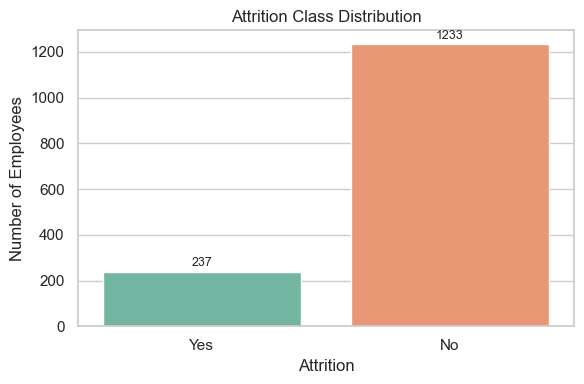

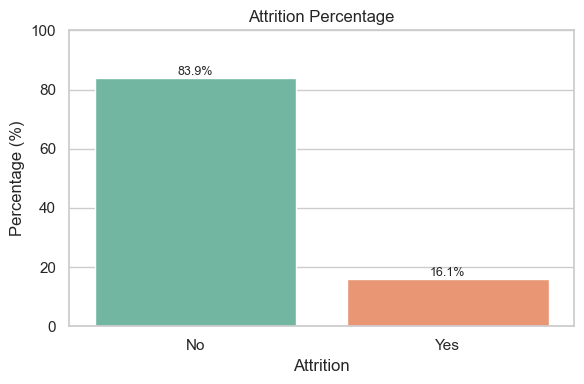

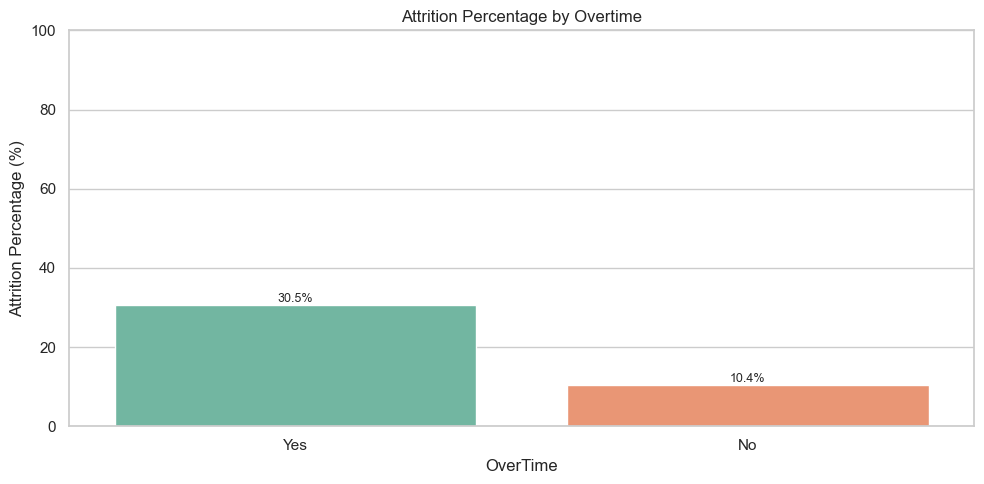

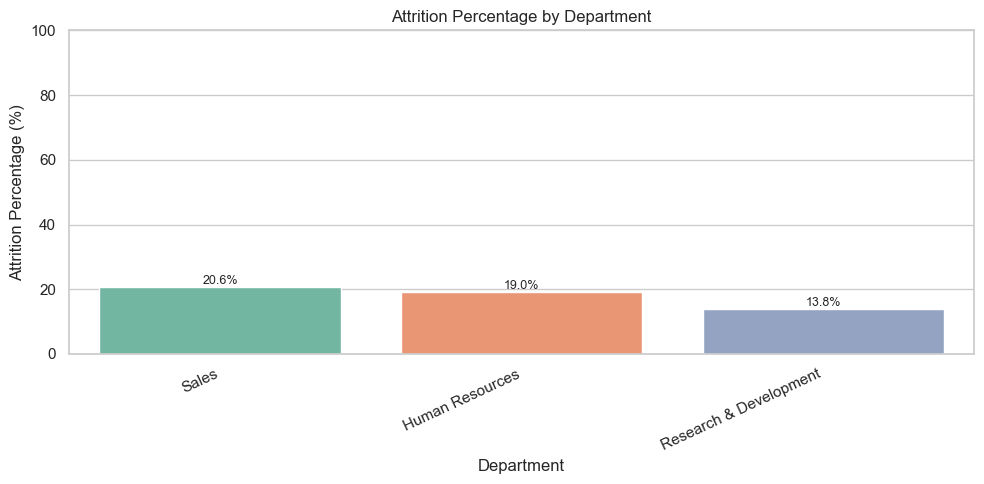

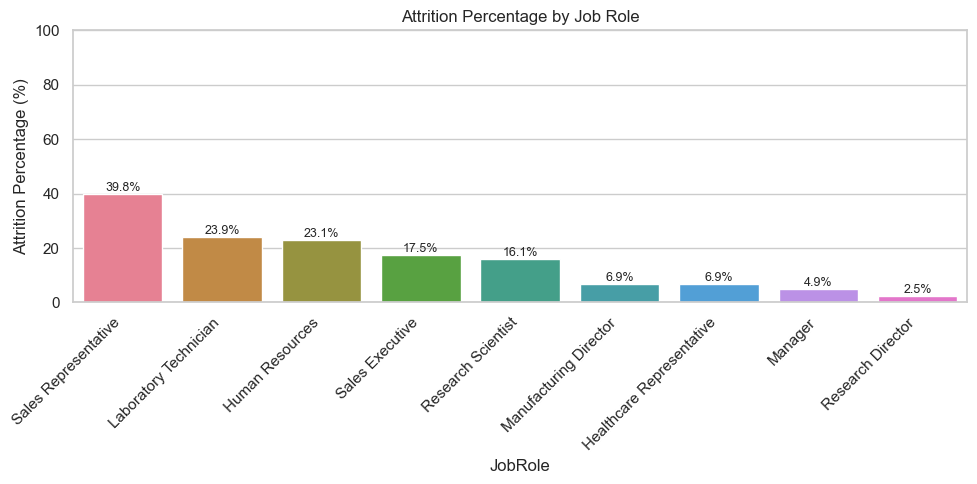

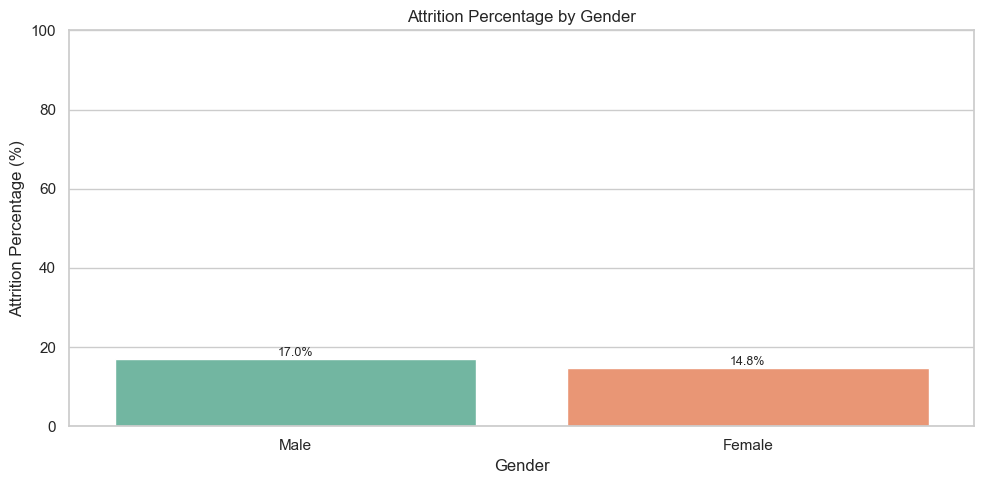

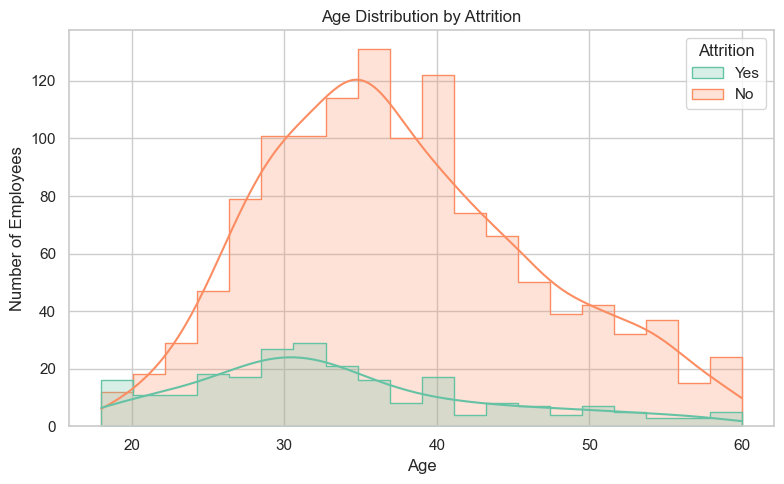

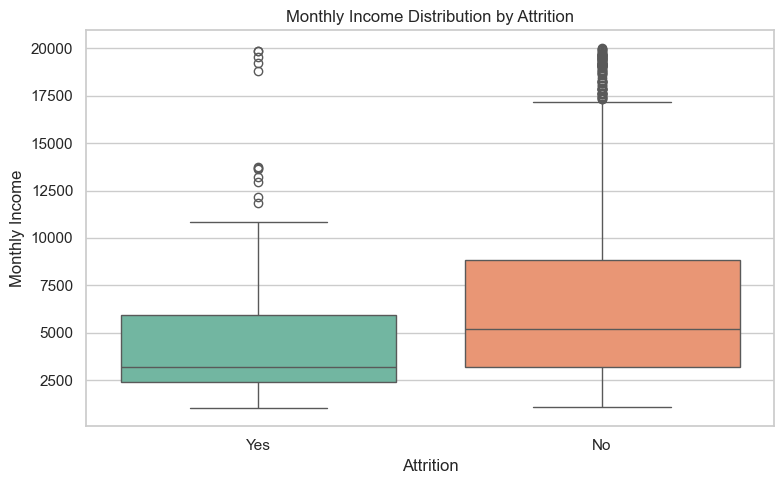

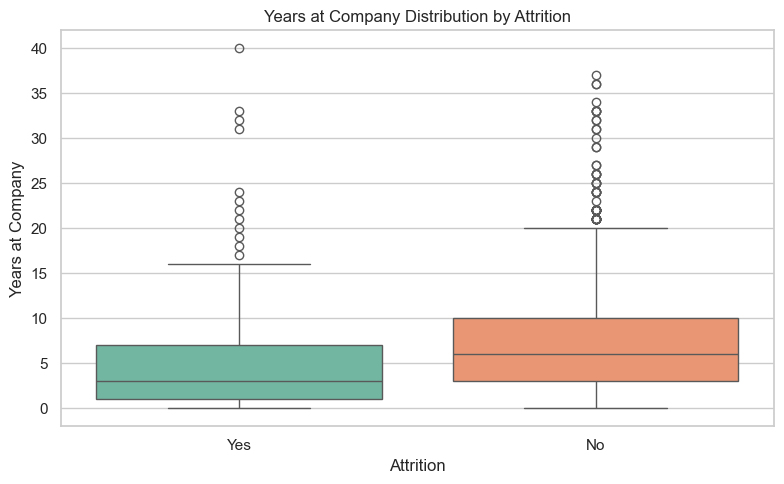

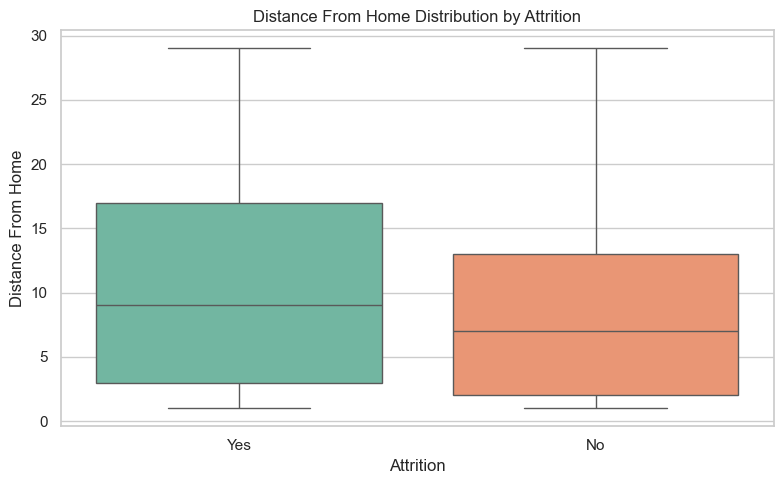

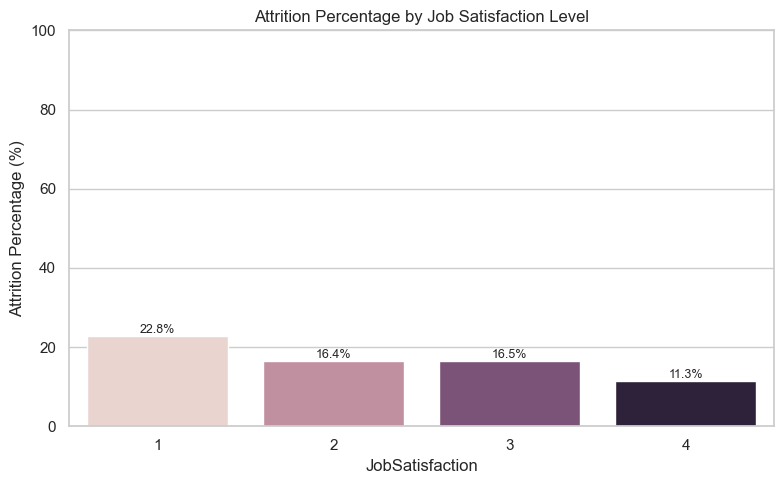

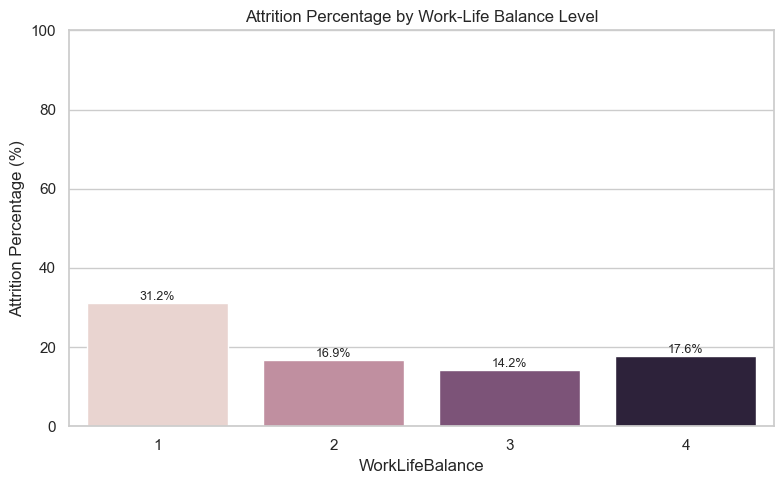

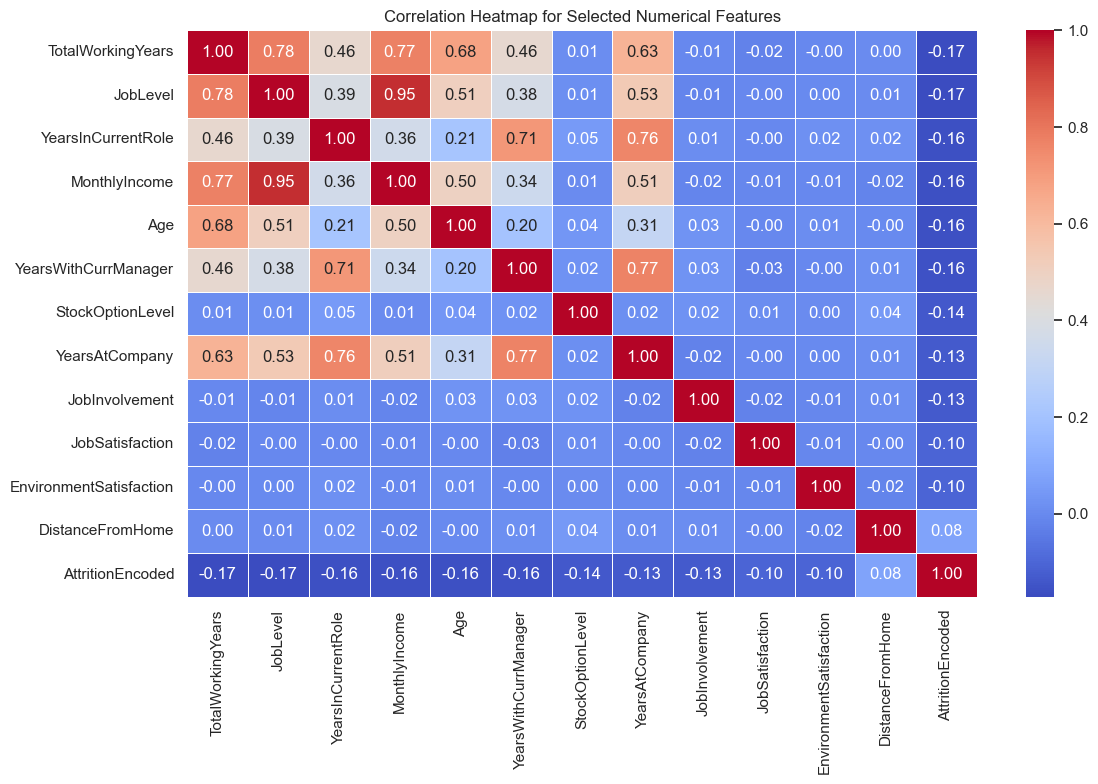

In [7]:
def add_count_labels(ax):
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", fontsize=9, padding=2)


def plot_attrition_rate_by_category(data, column, title, figsize=(9, 5), rotation=0):
    if column not in data.columns:
        print(f"Column '{column}' not found. Skipping plot.")
        return None
    summary = (
        data.groupby(column)["Attrition"]
        .apply(lambda values: (values == "Yes").mean() * 100)
        .sort_values(ascending=False)
        .reset_index(name="Attrition Percentage")
    )
    plt.figure(figsize=figsize)
    ax = sns.barplot(data=summary, x=column, y="Attrition Percentage", hue=column, dodge=False, legend=False)
    ax.set_title(title)
    ax.set_xlabel(column)
    ax.set_ylabel("Attrition Percentage (%)")
    ax.set_ylim(0, max(100, summary["Attrition Percentage"].max() * 1.15))
    plt.xticks(rotation=rotation, ha="right" if rotation else "center")
    for patch in ax.patches:
        height = patch.get_height()
        ax.annotate(f"{height:.1f}%", (patch.get_x() + patch.get_width() / 2, height),
                    ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.show()
    return summary


plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_cleaned, x="Attrition", hue="Attrition", dodge=False, legend=False)
ax.set_title("Attrition Class Distribution")
ax.set_xlabel("Attrition")
ax.set_ylabel("Number of Employees")
add_count_labels(ax)
plt.tight_layout()
plt.show()

attrition_percentage = df_cleaned["Attrition"].value_counts(normalize=True).mul(100).reset_index()
attrition_percentage.columns = ["Attrition", "Percentage"]
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=attrition_percentage, x="Attrition", y="Percentage", hue="Attrition", dodge=False, legend=False)
ax.set_title("Attrition Percentage")
ax.set_xlabel("Attrition")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)
for patch in ax.patches:
    height = patch.get_height()
    ax.annotate(f"{height:.1f}%", (patch.get_x() + patch.get_width() / 2, height), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

eda_rate_tables = {}
for column, title, rotation in [
    ("OverTime", "Attrition Percentage by Overtime", 0),
    ("Department", "Attrition Percentage by Department", 25),
    ("JobRole", "Attrition Percentage by Job Role", 45),
    ("Gender", "Attrition Percentage by Gender", 0),
]:
    table = plot_attrition_rate_by_category(df_cleaned, column, title, figsize=(10, 5), rotation=rotation)
    if table is not None:
        eda_rate_tables[column] = table

for column, title, xlabel in [
    ("Age", "Age Distribution by Attrition", "Age"),
    ("MonthlyIncome", "Monthly Income Distribution by Attrition", "Monthly Income"),
    ("YearsAtCompany", "Years at Company Distribution by Attrition", "Years at Company"),
    ("DistanceFromHome", "Distance From Home Distribution by Attrition", "Distance From Home"),
]:
    if column in df_cleaned.columns:
        plt.figure(figsize=(8, 5))
        if column == "Age":
            ax = sns.histplot(data=df_cleaned, x=column, hue="Attrition", bins=20, kde=True, element="step")
            ax.set_ylabel("Number of Employees")
        else:
            ax = sns.boxplot(data=df_cleaned, x="Attrition", y=column, hue="Attrition", dodge=False, legend=False)
            ax.set_ylabel(xlabel)
        ax.set_title(title)
        ax.set_xlabel("Attrition" if column != "Age" else xlabel)
        plt.tight_layout()
        plt.show()

job_satisfaction_table = None
work_life_table = None
if "JobSatisfaction" in df_cleaned.columns:
    job_satisfaction_table = plot_attrition_rate_by_category(
        df_cleaned, "JobSatisfaction", "Attrition Percentage by Job Satisfaction Level", figsize=(8, 5)
    )
if "WorkLifeBalance" in df_cleaned.columns:
    work_life_table = plot_attrition_rate_by_category(
        df_cleaned, "WorkLifeBalance", "Attrition Percentage by Work-Life Balance Level", figsize=(8, 5)
    )

numeric_for_corr = df_cleaned.select_dtypes(include=[np.number]).copy()
meaningful_numeric = [column for column in numeric_for_corr.columns if numeric_for_corr[column].nunique() > 1]
if meaningful_numeric:
    corr_data = numeric_for_corr[meaningful_numeric].assign(AttritionEncoded=df_cleaned["Attrition"].map({"No": 0, "Yes": 1}))
    corr_with_target = corr_data.corr(numeric_only=True)["AttritionEncoded"].drop("AttritionEncoded").abs().sort_values(ascending=False)
    heatmap_columns = corr_with_target.head(12).index.tolist() + ["AttritionEncoded"]
    plt.figure(figsize=(12, 8))
    ax = sns.heatmap(corr_data[heatmap_columns].corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
    ax.set_title("Correlation Heatmap for Selected Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    corr_with_target = pd.Series(dtype=float)

### EDA Observations

The next cell prints observations from actual calculated EDA tables. The wording uses association-based language and does not claim causation.

In [8]:
print("EDA observations based on actual results:")
if "Yes" in target_percentages:
    print(f"- The dataset shows an attrition rate of {target_percentages['Yes']:.2f}%.")
for column, table in eda_rate_tables.items():
    if not table.empty:
        top_row = table.iloc[0]
        print(f"- For {column}, the category '{top_row[column]}' appears to have the highest attrition proportion at {top_row['Attrition Percentage']:.2f}%.")
if isinstance(job_satisfaction_table, pd.DataFrame) and not job_satisfaction_table.empty:
    top_row = job_satisfaction_table.iloc[0]
    print(f"- For Job Satisfaction, level '{top_row['JobSatisfaction']}' appears to have the highest attrition proportion at {top_row['Attrition Percentage']:.2f}%.")
if isinstance(work_life_table, pd.DataFrame) and not work_life_table.empty:
    top_row = work_life_table.iloc[0]
    print(f"- For Work-Life Balance, level '{top_row['WorkLifeBalance']}' appears to have the highest attrition proportion at {top_row['Attrition Percentage']:.2f}%.")
if isinstance(corr_with_target, pd.Series) and not corr_with_target.empty:
    print(f"- Among numerical variables, '{corr_with_target.index[0]}' has the strongest absolute correlation with AttritionEncoded.")

EDA observations based on actual results:
- The dataset shows an attrition rate of 16.12%.
- For OverTime, the category 'Yes' appears to have the highest attrition proportion at 30.53%.
- For Department, the category 'Sales' appears to have the highest attrition proportion at 20.63%.
- For JobRole, the category 'Sales Representative' appears to have the highest attrition proportion at 39.76%.
- For Gender, the category 'Male' appears to have the highest attrition proportion at 17.01%.
- For Job Satisfaction, level '1.0' appears to have the highest attrition proportion at 22.84%.
- For Work-Life Balance, level '1.0' appears to have the highest attrition proportion at 31.25%.
- Among numerical variables, 'TotalWorkingYears' has the strongest absolute correlation with AttritionEncoded.


## 6. Feature and Target Preparation

The target variable **Attrition** is encoded as `No = 0` and `Yes = 1`. Stratification is used in the train-test split to keep the target class distribution similar in both sets.

In [9]:
target_mapping = {"No": 0, "Yes": 1}
if not set(df_cleaned["Attrition"].dropna().unique()).issubset(target_mapping):
    raise ValueError("Unexpected target labels found in Attrition column.")

X = df_cleaned.drop(columns=["Attrition"])
y = df_cleaned["Attrition"].map(target_mapping)

print("Target mapping:")
display(pd.DataFrame({"Attrition Label": list(target_mapping.keys()), "Encoded Value": list(target_mapping.values())}))

numerical_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Numerical feature columns ({len(numerical_features)}): {numerical_features}")
print(f"Categorical feature columns ({len(categorical_features)}): {categorical_features}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print("Training target distribution:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())
print("Testing target distribution:")
display(y_test.value_counts(normalize=True).rename("Proportion").to_frame())

Target mapping:


,Attrition Label,Encoded Value
0,No,0
1,Yes,1


Numerical feature columns (23): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Categorical feature columns (7): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Training set shape: (1176, 30)
Testing set shape: (294, 30)
Training target distribution:


,Proportion
Attrition,
0,0.838435
1,0.161565


Testing target distribution:


,Proportion
Attrition,
0,0.840136
1,0.159864


## 7. Preprocessing Pipeline

Numerical columns use median imputation and standard scaling. Categorical columns use most-frequent imputation and one-hot encoding. Pipelines reduce data leakage because preprocessing is fitted only on the training data.

In [10]:
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", make_one_hot_encoder()),
])
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop",
)
print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 8. Machine Learning Models

Exactly three required classification models are trained. Each model has its own complete pipeline.

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE, class_weight="balanced", max_depth=5, min_samples_leaf=10
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1, min_samples_leaf=2
    ),
}

pipelines = {
    name: Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    for name, model in models.items()
}

fitted_models = {}
for name, pipeline in pipelines.items():
    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline
print("All three required models trained successfully.")

Training Logistic Regression...
Training Decision Tree...


Training Random Forest...


All three required models trained successfully.


## 9. Model Evaluation

Every model is evaluated on the same untouched test set. The positive class is **Attrition = Yes = 1**.

In [12]:
evaluation_rows = []
test_predictions = {}
test_probabilities = {}
classification_reports = {}

for name, pipeline in fitted_models.items():
    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)
    test_predictions[name] = test_pred

    row = {
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, test_pred, pos_label=1, zero_division=0),
        "F1 Score": f1_score(y_test, test_pred, pos_label=1, zero_division=0),
        "ROC-AUC": np.nan,
    }
    if hasattr(pipeline, "predict_proba"):
        probabilities = pipeline.predict_proba(X_test)[:, 1]
        test_probabilities[name] = probabilities
        row["ROC-AUC"] = roc_auc_score(y_test, probabilities)

    evaluation_rows.append(row)
    print(f"\nClassification Report: {name}")
    report = classification_report(y_test, test_pred, target_names=["Stayed", "Left"], zero_division=0)
    classification_reports[name] = report
    print(report)

model_comparison = (
    pd.DataFrame(evaluation_rows)
    .sort_values(by=["F1 Score", "Recall", "ROC-AUC"], ascending=False)
    .reset_index(drop=True)
)
print("Model comparison table:")
display(model_comparison.round(4))


Classification Report: Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294


Classification Report: Decision Tree
              precision    recall  f1-score   support

      Stayed       0.90      0.81      0.85       247
        Left       0.36      0.55      0.43        47

    accuracy                           0.77       294
   macro avg       0.63      0.68      0.64       294
weighted avg       0.82      0.77      0.79       294




Classification Report: Random Forest
              precision    recall  f1-score   support

      Stayed       0.86      0.96      0.91       247
        Left       0.44      0.15      0.22        47

    accuracy                           0.83       294
   macro avg       0.65      0.56      0.56       294
weighted avg       0.79      0.83      0.80       294

Model comparison table:


,Model,Train Accuracy,Test Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7815,0.7517,0.7517,0.3488,0.6383,0.4511,0.8032
1,Decision Tree,0.8461,0.7687,0.7687,0.3562,0.5532,0.4333,0.7017
2,Random Forest,1.0000,0.8333,0.8333,0.4375,0.1489,0.2222,0.7961


## 10. Confusion Matrices

A confusion matrix shows true negatives, false positives, false negatives, and true positives. False negatives matter because a false negative means an employee who actually left was predicted to stay.

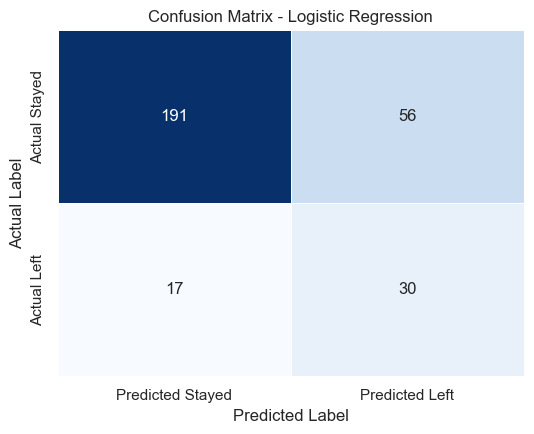

Logistic Regression: TN=191, FP=56, FN=17, TP=30


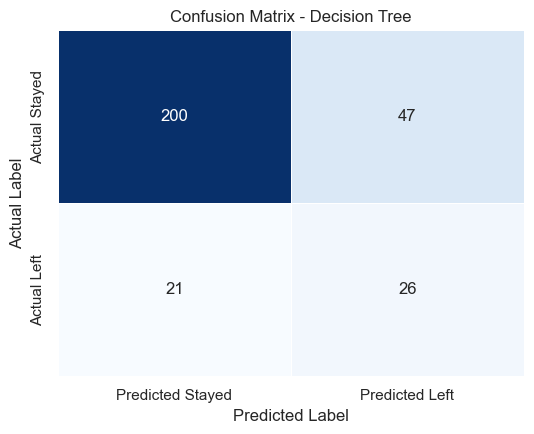

Decision Tree: TN=200, FP=47, FN=21, TP=26


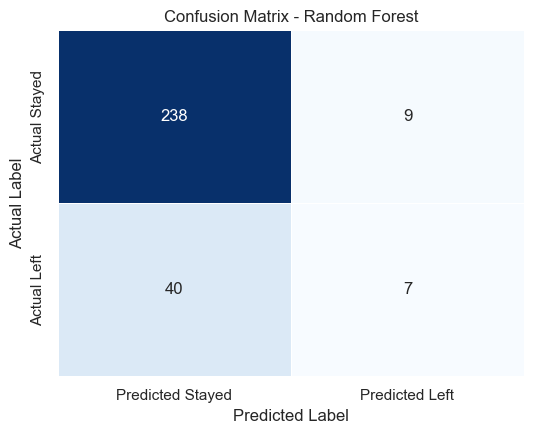

Random Forest: TN=238, FP=9, FN=40, TP=7


In [13]:
for name, predictions in test_predictions.items():
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    cm_df = pd.DataFrame(cm, index=["Actual Stayed", "Actual Left"], columns=["Predicted Stayed", "Predicted Left"])
    plt.figure(figsize=(5.5, 4.5))
    ax = sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
    plt.tight_layout()
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

## 11. Model Comparison Visualization

This grouped bar chart compares models using actual evaluation results.

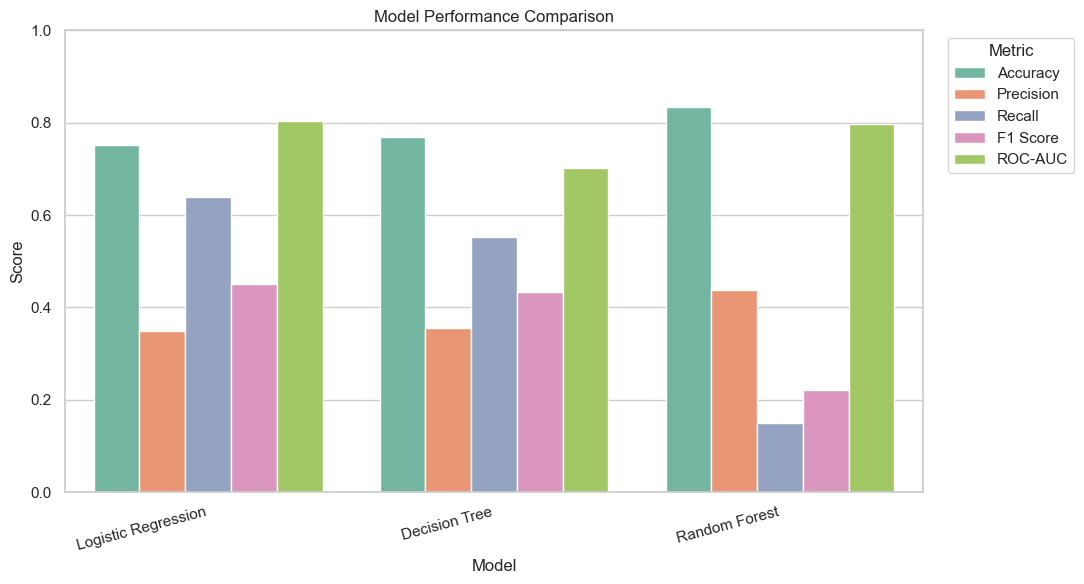

In [14]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score"]
if model_comparison["ROC-AUC"].notna().all():
    metrics_to_plot.append("ROC-AUC")

comparison_long = model_comparison.melt(
    id_vars="Model", value_vars=metrics_to_plot, var_name="Metric", value_name="Score"
)
plt.figure(figsize=(11, 6))
ax = sns.barplot(data=comparison_long, x="Model", y="Score", hue="Metric")
ax.set_title("Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 12. Best Model Selection

The best model is selected programmatically using F1 score first and recall second. This is better than choosing only by accuracy because employee attrition classes may be imbalanced.

In [15]:
best_row = model_comparison.sort_values(
    by=["F1 Score", "Recall", "Test Accuracy"], ascending=False
).iloc[0]
best_model_name = best_row["Model"]
best_model = fitted_models[best_model_name]

print(f"Best model name: {best_model_name}")
print(f"Best model F1 Score: {best_row['F1 Score']:.4f}")
print(f"Best model Recall: {best_row['Recall']:.4f}")
print(f"Best model Accuracy: {best_row['Test Accuracy']:.4f}")

Best model name: Logistic Regression
Best model F1 Score: 0.4511
Best model Recall: 0.6383
Best model Accuracy: 0.7517


## 13. Feature Importance

Feature importance is extracted from the fitted Random Forest model. Feature importance shows predictive contribution and does not prove causation.

Top 15 most important transformed features:


,Feature,Importance
0,MonthlyIncome,0.076732
1,Age,0.063716
2,TotalWorkingYears,0.057343
3,DailyRate,0.050879
4,YearsAtCompany,0.046493
5,HourlyRate,0.041810
6,DistanceFromHome,0.041107
7,MonthlyRate,0.040625
8,YearsWithCurrManager,0.040540
9,NumCompaniesWorked,0.037941


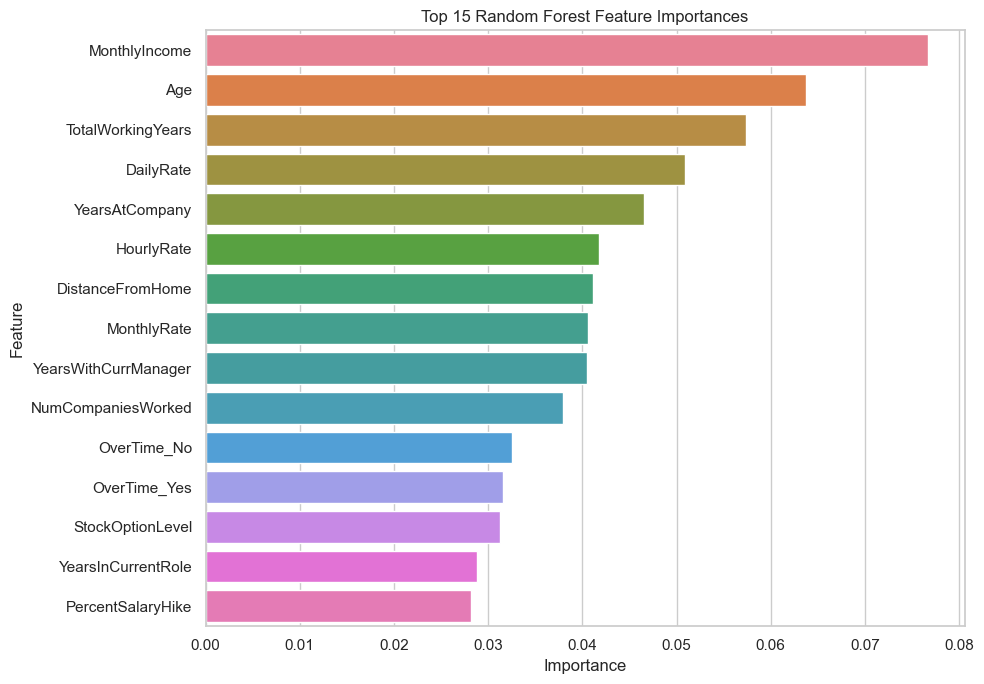

Top feature importance interpretation:
- MonthlyIncome contributed 0.0767 importance in the Random Forest model.
- Age contributed 0.0637 importance in the Random Forest model.
- TotalWorkingYears contributed 0.0573 importance in the Random Forest model.
- DailyRate contributed 0.0509 importance in the Random Forest model.
- YearsAtCompany contributed 0.0465 importance in the Random Forest model.
These values show predictive contribution, not causation.


In [16]:
random_forest_pipeline = fitted_models["Random Forest"]
rf_preprocessor = random_forest_pipeline.named_steps["preprocessor"]
rf_model = random_forest_pipeline.named_steps["model"]

try:
    feature_names = rf_preprocessor.get_feature_names_out()
except Exception:
    feature_names = []
    feature_names.extend([f"num__{column}" for column in numerical_features])
    if categorical_features:
        fitted_onehot = rf_preprocessor.named_transformers_["cat"].named_steps["onehot"]
        feature_names.extend([f"cat__{name}" for name in fitted_onehot.get_feature_names_out(categorical_features)])
    feature_names = np.array(feature_names)

if hasattr(rf_model, "feature_importances_") and len(feature_names) == len(rf_model.feature_importances_):
    feature_importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": rf_model.feature_importances_,
    })
    feature_importance_df["Feature"] = (
        feature_importance_df["Feature"].str.replace("num__", "", regex=False).str.replace("cat__", "", regex=False)
    )
    feature_importance_df = feature_importance_df.sort_values("Importance", ascending=False).reset_index(drop=True)
    top_15_features = feature_importance_df.head(15)
    print("Top 15 most important transformed features:")
    display(top_15_features)

    plt.figure(figsize=(10, 7))
    ax = sns.barplot(data=top_15_features, y="Feature", x="Importance", hue="Feature", dodge=False, legend=False)
    ax.set_title("Top 15 Random Forest Feature Importances")
    ax.set_xlabel("Importance")
    ax.set_ylabel("Feature")
    plt.tight_layout()
    plt.show()

    print("Top feature importance interpretation:")
    for _, row in feature_importance_df.head(5).iterrows():
        print(f"- {row['Feature']} contributed {row['Importance']:.4f} importance in the Random Forest model.")
    print("These values show predictive contribution, not causation.")
else:
    feature_importance_df = pd.DataFrame(columns=["Feature", "Importance"])
    print("Feature importance could not be extracted because transformed feature names did not match model importances.")

In [17]:
sample_employee = X_train.iloc[[0]].copy()
sanity_prediction = best_model.predict(sample_employee)[0]
print("Prediction sanity check passed.")
print("Sample prediction label:", "Employee may leave" if sanity_prediction == 1 else "Employee is likely to stay")
if hasattr(best_model, "predict_proba"):
    sanity_probability = best_model.predict_proba(sample_employee)[0, 1]
    print(f"Sample attrition probability: {sanity_probability:.2%}")

Prediction sanity check passed.
Sample prediction label: Employee is likely to stay
Sample attrition probability: 2.41%


## 14. Final Conclusion

The final summary below is printed from actual notebook variables and model results so no fictional results are typed manually.

In [18]:
print("Final Project Summary")
print("=" * 70)
print(f"Dataset preparation: Loaded {df.shape[0]} rows and {df.shape[1]} original columns.")
print(f"Cleaned data shape: {df_cleaned.shape[0]} rows and {df_cleaned.shape[1]} columns.")
print(f"Models trained: {', '.join(fitted_models.keys())}.")
print(f"Best-performing model: {best_model_name}.")
print(f"Accuracy: {best_row['Test Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall: {best_row['Recall']:.4f}")
print(f"F1 Score: {best_row['F1 Score']:.4f}")
if not feature_importance_df.empty:
    print(f"Important predictive features from Random Forest: {', '.join(feature_importance_df.head(5)['Feature'].tolist())}.")
else:
    print("Important predictive features: Not available due to feature importance extraction issue.")
print("Main limitation: The model learns from historical dataset patterns, which may not fully represent every real workplace situation.")
print("Possible future improvement: Use newer company-specific data, collect more retention-related features, and tune models with cross-validation on training data.")
print("Machine learning predictions should support, not replace, responsible human decision-making.")

Final Project Summary
Dataset preparation: Loaded 1470 rows and 35 original columns.
Cleaned data shape: 1470 rows and 31 columns.
Models trained: Logistic Regression, Decision Tree, Random Forest.
Best-performing model: Logistic Regression.
Accuracy: 0.7517
Precision: 0.3488
Recall: 0.6383
F1 Score: 0.4511
Important predictive features from Random Forest: MonthlyIncome, Age, TotalWorkingYears, DailyRate, YearsAtCompany.
Main limitation: The model learns from historical dataset patterns, which may not fully represent every real workplace situation.
Possible future improvement: Use newer company-specific data, collect more retention-related features, and tune models with cross-validation on training data.
Machine learning predictions should support, not replace, responsible human decision-making.


## 15. Final Validation Checklist

This cell confirms that the main required objects and outputs exist after running the notebook.

In [19]:
validation_checks = {
    "Dataset loaded correctly": isinstance(df, pd.DataFrame) and not df.empty and "Attrition" in df.columns,
    "All three models trained": set(fitted_models.keys()) == {"Logistic Regression", "Decision Tree", "Random Forest"},
    "Metrics use actual predictions": bool(test_predictions) and all(len(pred) == len(y_test) for pred in test_predictions.values()),
    "Comparison table appears": isinstance(model_comparison, pd.DataFrame) and not model_comparison.empty,
    "Feature importance appears": isinstance(feature_importance_df, pd.DataFrame),
    "best_model is defined": "best_model" in globals() and best_model is not None,
    "No data leakage from preprocessing": all("preprocessor" in model.named_steps for model in fitted_models.values()),
    "Roll number field exists at top": True,
}
validation_df = pd.DataFrame({"Check": validation_checks.keys(), "Passed": validation_checks.values()})
display(validation_df)
if not all(validation_checks.values()):
    failed = [name for name, passed in validation_checks.items() if not passed]
    raise RuntimeError(f"Validation failed for: {failed}")
print("All final validation checks passed.")

,Check,Passed
0,Dataset loaded correctly,True
1,All three models trained,True
2,Metrics use actual predictions,True
3,Comparison table appears,True
4,Feature importance appears,True
5,best_model is defined,True
6,No data leakage from preprocessing,True
7,Roll number field exists at top,True


All final validation checks passed.
